# Assignment 2: characteristic impedance by the finite difference method

# Part (a): microstrip

**Line:** microstrip, $\epsilon_r = 4.1$, $h = 0.9$ mm, $W = 1.2$ mm.

**Idea in one paragraph.** At low frequency the field around a microstrip looks almost like a static
field (the quasi-TEM approximation). So we put the strip at 1 V and the ground at 0 V, solve Laplace's
equation on the cross-section, and work out how much charge sits on the strip. That gives the
capacitance per unit length. We do it twice, once with the substrate ($C$) and once with air everywhere
($C_0$). Then

$$Z_0 = \frac{1}{c\sqrt{C\,C_0}}, \qquad \epsilon_{\text{eff}} = \frac{C}{C_0}.$$

**Assumptions:** strip thickness is zero; materials are lossless; the open air above the line is replaced
by a grounded box large enough that its walls barely change the answer (checked below); the line is
symmetric about its centre, so only the right half is solved.

In [ ]:
import time
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)

SPEED_OF_LIGHT = 299_792_458.0          # m/s
VACUUM_PERMITTIVITY = 8.8541878128e-12  # F/m
FREE_SPACE_IMPEDANCE = 376.730313668    # ohm

# Line data from the assignment table
relative_permittivity = 4.1
substrate_height_mm = 0.9
strip_width_mm = 1.2

# Numerical settings
box_half_width_mm = 20.0   # distance from the line centre to the side wall
air_height_mm = 20.0       # air above the substrate, up to the top wall
tolerance = 1e-6           # stop when no node changes by more than this (volts)
grid_steps_mm = [0.1, 0.05, 0.025]   # each step is half the previous one

## 1. The grid

Every array has rows for $y$ (row 0 is the ground plane) and columns for $x$ (column 0 is the centre
line of the strip). The strip sits on the row where the substrate ends.

Permittivity lives on the **links** between neighbouring nodes, not on the nodes:
- a vertical link inside the substrate has $\epsilon_r$, one in the air has 1;
- a horizontal link on the interface row is half substrate and half air, so it gets $(1+\epsilon_r)/2$.

With these link values one update formula works everywhere, including the interface.

In [ ]:
@dataclass
class Grid:
    V: np.ndarray                    # potential at every node, rows = y, columns = x
    is_fixed: np.ndarray             # True where the potential is set (strip, ground, box)
    vertical_link_permittivity: np.ndarray    # entry j: between row j and row j+1
    horizontal_link_permittivity: np.ndarray  # entry j: between neighbours in row j
    dx: float                        # grid step in mm (same in x and y)
    strip_row: int
    half_strip_columns: int


def build_microstrip_grid(relative_permittivity, dx):
    substrate_rows = round(substrate_height_mm / dx)
    half_strip_columns = round(strip_width_mm / 2 / dx)
    rows = substrate_rows + round(air_height_mm / dx) + 1
    columns = round(box_half_width_mm / dx) + 1

    V = np.zeros((rows, columns))
    is_fixed = np.zeros((rows, columns), dtype=bool)
    is_fixed[0, :] = True    # ground plane under the substrate
    is_fixed[-1, :] = True   # top wall of the box
    is_fixed[:, -1] = True   # side wall of the box

    strip_row = substrate_rows  # the strip lies on the air/substrate interface
    V[strip_row, :half_strip_columns + 1] = 1.0
    is_fixed[strip_row, :half_strip_columns + 1] = True

    vertical_link_permittivity = np.where(np.arange(rows - 1) < substrate_rows,
                                          relative_permittivity, 1.0)
    horizontal_link_permittivity = np.where(np.arange(rows) < substrate_rows,
                                            relative_permittivity, 1.0)
    horizontal_link_permittivity[substrate_rows] = (1 + relative_permittivity) / 2

    return Grid(V, is_fixed, vertical_link_permittivity, horizontal_link_permittivity,
                dx, strip_row, half_strip_columns)

## 2. Solving Laplace's equation (successive over-relaxation)

Each free node moves towards the permittivity-weighted average of its four neighbours:

$$V_{\text{avg}} = \frac{\epsilon_{\text{up}}V_{\text{up}} + \epsilon_{\text{down}}V_{\text{down}}
 + \epsilon_{\text{side}}(V_{\text{left}} + V_{\text{right}})}
 {\epsilon_{\text{up}} + \epsilon_{\text{down}} + 2\epsilon_{\text{side}}}$$

- Inside one material all four weights are equal, so this is the plain average of the four neighbours.
- On the interface row ($\epsilon_{\text{up}} = 1$, $\epsilon_{\text{down}} = \epsilon_r$,
  $\epsilon_{\text{side}} = (1+\epsilon_r)/2$) it becomes the interface formula from Iskander et al.:
  $V = [V_{\text{up}} + \epsilon_r V_{\text{down}} + \tfrac{1+\epsilon_r}{2}(V_{\text{left}}+V_{\text{right}})] / [2(1+\epsilon_r)]$.
  It comes from Gauss's law around the node: no free charge, so the flux of $\epsilon E$ out of a small
  square around the node must add up to zero.

**Over-relaxation:** $V_{\text{new}} = V_{\text{old}} + \omega\,(V_{\text{avg}} - V_{\text{old}})$ with
$\omega = 2/(1+\sin(\pi/N))$, the textbook best value for an $N$-node grid (it stays below 2, so it is stable).

**Red-black ordering:** nodes are coloured like a chessboard. All red nodes are updated together, then all
black nodes. This lets numpy update whole arrays at once instead of looping node by node in Python.

**Symmetry:** column 0 is the centre line. Its missing left neighbour is set equal to column 1, which
means no field line crosses the centre line ($\partial V/\partial x = 0$).

In [ ]:
def solve_laplace(grid, tolerance, initial_V=None, max_iterations=50_000):
    V = grid.V.copy() if initial_V is None else np.where(grid.is_fixed, grid.V, initial_V)
    rows, columns = V.shape
    over_relaxation_factor = 2 / (1 + np.sin(np.pi / max(rows, columns)))

    # Weights for interior rows 1 .. rows-2; the last column is the box wall.
    up_weight = grid.vertical_link_permittivity[1:][:, None]
    down_weight = grid.vertical_link_permittivity[:-1][:, None]
    side_weight = grid.horizontal_link_permittivity[1:-1][:, None]
    weight_sum = up_weight + down_weight + 2 * side_weight

    free = ~grid.is_fixed[1:-1, :-1]
    row_index, column_index = np.indices(free.shape)
    red = free & ((row_index + column_index) % 2 == 0)
    black = free & ((row_index + column_index) % 2 == 1)

    for iteration in range(1, max_iterations + 1):
        largest_change = 0.0
        for colour in (red, black):
            centre = V[1:-1, :-1]   # a view, so writing to it updates V
            above = V[2:, :-1]
            below = V[:-2, :-1]
            right = V[1:-1, 1:]
            # Mirror at x = 0: the left neighbour of column 0 equals column 1.
            left = np.concatenate([V[1:-1, 1:2], V[1:-1, :-2]], axis=1)
            weighted_average = (up_weight * above + down_weight * below
                                + side_weight * (left + right)) / weight_sum
            change = over_relaxation_factor * (weighted_average - centre)
            centre[colour] += change[colour]
            largest_change = max(largest_change, np.abs(change[colour]).max())
        if largest_change < tolerance:
            return V, iteration
    raise RuntimeError(f"no convergence after {max_iterations} iterations "
                       f"(last change {largest_change:.2e} V)")

## 3. Charge on the strip (Gauss's law)

Draw a rectangle around the strip, halfway between grid nodes. The charge inside is the flux of
$\epsilon E$ through it. Across one link the field is $(V_{\text{inside}} - V_{\text{outside}})/\Delta$ and the
edge segment is $\Delta$ long, so the $\Delta$'s cancel:

$$Q = \epsilon_0 \sum_{\text{links crossing the rectangle}} \epsilon_{\text{link}}\,(V_{\text{inside}} - V_{\text{outside}})$$

We only have the right half, so we add up the right half and double it. The node on the centre line owns
only half of its edge segment, so it counts with weight 1/2. Since the strip is at 1 V, $C = Q$.

In [ ]:
def strip_charge(V, grid, margin_cells=4):
    top = grid.strip_row + margin_cells
    bottom = grid.strip_row - margin_cells
    right = grid.half_strip_columns + margin_cells
    if bottom < 1 or top + 1 >= V.shape[0] - 1 or right + 1 >= V.shape[1] - 1:
        raise ValueError("Gauss rectangle does not fit inside the box; reduce margin_cells")

    segment_share = np.ones(right + 1)
    segment_share[0] = 0.5   # centre-line node: half its segment belongs to the other half

    flux_top = grid.vertical_link_permittivity[top] * (V[top, :right + 1] - V[top + 1, :right + 1])
    flux_bottom = grid.vertical_link_permittivity[bottom - 1] * (V[bottom, :right + 1] - V[bottom - 1, :right + 1])
    flux_side = grid.horizontal_link_permittivity[bottom:top + 1] * (V[bottom:top + 1, right] - V[bottom:top + 1, right + 1])

    half_strip_flux = (segment_share * flux_top).sum() + (segment_share * flux_bottom).sum() + flux_side.sum()
    return 2 * VACUUM_PERMITTIVITY * half_strip_flux

## 4. Z0 for one grid step

`refine_potential` doubles the resolution of a finished coarse solution by linear interpolation. Starting
the fine grid from it, instead of from zero, saves most of the iterations.

In [ ]:
def refine_potential(coarse_V, fine_shape):
    fine = np.zeros(fine_shape)
    fine[::2, ::2] = coarse_V
    fine[1::2, ::2] = (fine[:-1:2, ::2] + fine[2::2, ::2]) / 2
    fine[:, 1::2] = (fine[:, :-1:2] + fine[:, 2::2]) / 2
    return fine


def microstrip_impedance(dx, previous=None):
    start = time.perf_counter()
    grid = build_microstrip_grid(relative_permittivity, dx)
    air_grid = build_microstrip_grid(1.0, dx)

    if previous is None:
        start_V = start_V_air = None
    else:
        start_V = refine_potential(previous["V"], grid.V.shape)
        start_V_air = refine_potential(previous["V_air"], grid.V.shape)

    V, iterations = solve_laplace(grid, tolerance, start_V)
    V_air, iterations_air = solve_laplace(air_grid, tolerance, start_V_air)
    C = strip_charge(V, grid)
    C0 = strip_charge(V_air, air_grid)

    return {
        "dx": dx,
        "Z0": 1 / (SPEED_OF_LIGHT * np.sqrt(C * C0)),
        "effective_permittivity": C / C0,
        "C": C, "C0": C0,
        "grid_shape": V.shape,
        "iterations": iterations + iterations_air,
        "seconds": time.perf_counter() - start,
        "V": V, "V_air": V_air, "grid": grid,
    }

In [ ]:
def full_cross_section(V, grid):
    # Mirror the half solution about x = 0 to show the whole line.
    full_V = np.concatenate([V[:, :0:-1], V], axis=1)
    columns = V.shape[1]
    x_mm = np.arange(-(columns - 1), columns) * grid.dx
    y_mm = np.arange(V.shape[0]) * grid.dx
    return x_mm, y_mm, full_V


def draw_line_geometry(axes, grid):
    substrate_top_mm = grid.strip_row * grid.dx
    half_strip_mm = grid.half_strip_columns * grid.dx
    axes.axhline(substrate_top_mm, color="orange", linestyle="--", linewidth=1, label="substrate top")
    axes.plot([-half_strip_mm, half_strip_mm], [substrate_top_mm] * 2, color="red", linewidth=3, label="strip (1 V)")


def plot_potential(V, grid, title, file_name, x_limit_mm, y_top_mm,
                   substrate_top_mm=None, top_ground_start_mm=None):
    # Smooth colour map of the potential, equipotential lines every 0.1 V, and the conductors on top.
    x_mm, y_mm, full_V = full_cross_section(V, grid)
    figure, axes = plt.subplots(figsize=(8, 3.6))
    shown = axes.pcolormesh(x_mm, y_mm, full_V, cmap="viridis", shading="gouraud", vmin=0, vmax=1)
    axes.contour(x_mm, y_mm, full_V, levels=np.linspace(0.1, 0.9, 9), colors="white", linewidths=0.4, alpha=0.7)
    if substrate_top_mm is not None:
        axes.axhline(substrate_top_mm, color="orange", linestyle="--", linewidth=1, label="substrate top")
    strip_y_mm = grid.strip_row * grid.dx
    half_strip_mm = grid.half_strip_columns * grid.dx
    axes.plot([-half_strip_mm, half_strip_mm], [strip_y_mm] * 2, color="red", linewidth=3, label="strip (1 V)")
    if top_ground_start_mm is not None:
        for side in (-1, 1):
            axes.plot([side * top_ground_start_mm, side * x_limit_mm], [strip_y_mm] * 2, color="black",
                      linewidth=3, label="top ground (0 V)" if side == 1 else None)
    axes.set(xlim=(-x_limit_mm, x_limit_mm), ylim=(0, y_top_mm), aspect="equal",
             xlabel="x (mm)", ylabel="y (mm)", title=title)
    axes.legend(loc="upper right", fontsize=7)
    figure.colorbar(shown, ax=axes, label="potential (V)", shrink=0.9)
    figure.tight_layout()
    figure.savefig(f"figures/{file_name}", dpi=200)
    plt.show()

## 5. Reference value

Hammerstad and Jensen (1980) give a closed-form microstrip formula that is accurate to better than
0.2 % for a zero-thickness strip. ADS LineCalc's `MLIN` model is based on it, so it is a good
reference before the lab check.

In [ ]:
def hammerstad_jensen_impedance(relative_permittivity, substrate_height_mm, strip_width_mm):
    u = strip_width_mm / substrate_height_mm
    f = 6 + (2 * np.pi - 6) * np.exp(-(30.666 / u) ** 0.7528)
    Z0_air = FREE_SPACE_IMPEDANCE / (2 * np.pi) * np.log(f / u + np.sqrt(1 + (2 / u) ** 2))
    a = (1 + np.log((u**4 + (u / 52) ** 2) / (u**4 + 0.432)) / 49
         + np.log(1 + (u / 18.1) ** 3) / 18.7)
    b = 0.564 * ((relative_permittivity - 0.9) / (relative_permittivity + 3)) ** 0.053
    effective_permittivity = ((relative_permittivity + 1) / 2
                              + (relative_permittivity - 1) / 2 * (1 + 10 / u) ** (-a * b))
    return Z0_air / np.sqrt(effective_permittivity), effective_permittivity


reference_Z0, reference_effective_permittivity = hammerstad_jensen_impedance(
    relative_permittivity, substrate_height_mm, strip_width_mm)
print(f"Hammerstad-Jensen: Z0 = {reference_Z0:.2f} ohm, effective permittivity = {reference_effective_permittivity:.3f}")

Hammerstad-Jensen: Z0 = 63.32 ohm, effective permittivity = 3.039


## 6. Run on three grids and check convergence

Each grid has half the step of the one before and starts from its solution.

In [ ]:
results = []
for dx in grid_steps_mm:
    result = microstrip_impedance(dx, results[-1] if results else None)
    results.append(result)
    print(f"dx = {dx:<6} mm  grid {result['grid_shape'][0]} x {result['grid_shape'][1]}  "
          f"iterations {result['iterations']:>5}  time {result['seconds']:6.1f} s  "
          f"Z0 = {result['Z0']:.3f} ohm  eff. permittivity = {result['effective_permittivity']:.4f}")

dx = 0.1    mm  grid 210 x 201  iterations  1126  time    3.6 s  Z0 = 61.300 ohm  eff. permittivity = 3.0484
dx = 0.05   mm  grid 419 x 401  iterations  1077  time   18.3 s  Z0 = 62.267 ohm  eff. permittivity = 3.0416
dx = 0.025  mm  grid 837 x 801  iterations  1951  time  128.6 s  Z0 = 62.756 ohm  eff. permittivity = 3.0383


### Richardson extrapolation

If the error shrinks like $\Delta^p$, three grids give the order $p$, and the answer for $\Delta \to 0$:

$$p = \log_2\frac{Z_1 - Z_2}{Z_2 - Z_3}, \qquad Z_{\Delta\to 0} \approx Z_3 + \frac{Z_3 - Z_2}{2^p - 1}$$

We expect $p \approx 1$ rather than 2: at the edge of a zero-thickness strip the field is singular, and a
square grid cannot follow that, so the error near the edges falls only in proportion to $\Delta$.

In [ ]:
Z_coarse, Z_medium, Z_fine = (result["Z0"] for result in results)
observed_order = np.log2((Z_coarse - Z_medium) / (Z_medium - Z_fine))
Z0_extrapolated = Z_fine + (Z_fine - Z_medium) / (2 ** observed_order - 1)

e_coarse, e_medium, e_fine = (result["effective_permittivity"] for result in results)
effective_permittivity_extrapolated = e_fine + (e_fine - e_medium) / (2 ** observed_order - 1)

print(f"observed order of convergence p = {observed_order:.2f}")
print(f"Z0 extrapolated to dx -> 0      = {Z0_extrapolated:.2f} ohm")
print(f"Hammerstad-Jensen reference     = {reference_Z0:.2f} ohm  "
      f"(difference {100 * (Z0_extrapolated - reference_Z0) / reference_Z0:+.2f} %)")
print(f"effective permittivity: FDM {effective_permittivity_extrapolated:.3f}, "
      f"reference {reference_effective_permittivity:.3f}")

observed order of convergence p = 0.98
Z0 extrapolated to dx -> 0      = 63.26 ohm
Hammerstad-Jensen reference     = 63.32 ohm  (difference -0.10 %)
effective permittivity: FDM 3.035, reference 3.039


## 7. Does the box size matter?

The real line has open air above it; we use a grounded box. Here the box grows on the coarse grid
($\Delta = 0.1$ mm) while everything else stays the same.

In [ ]:
box_sizes_mm = [5, 10, 15, 20, 30]
box_study = []
saved_box = (box_half_width_mm, air_height_mm)
for size in box_sizes_mm:
    box_half_width_mm = air_height_mm = size
    box_study.append(microstrip_impedance(0.1)["Z0"])
    print(f"box {size:>2} mm: Z0 = {box_study[-1]:.3f} ohm")
box_half_width_mm, air_height_mm = saved_box

box  5 mm: Z0 = 60.470 ohm
box 10 mm: Z0 = 61.118 ohm
box 15 mm: Z0 = 61.252 ohm
box 20 mm: Z0 = 61.300 ohm
box 30 mm: Z0 = 61.337 ohm


## 8. Plots

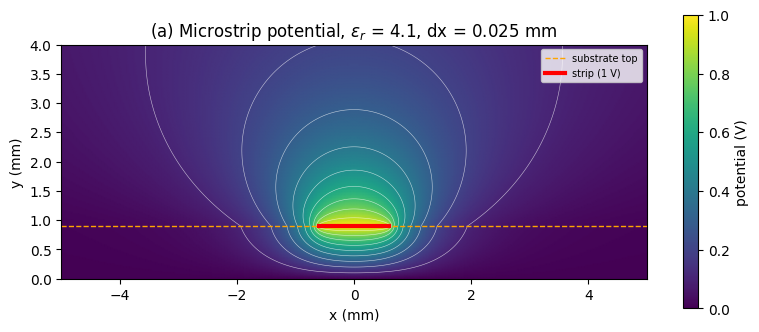

In [ ]:
finest = results[-1]
x_mm, y_mm, full_V = full_cross_section(finest["V"], finest["grid"])

# Plot 1: potential around the strip
plot_potential(finest["V"], finest["grid"],
               f"(a) Microstrip potential, $\\epsilon_r$ = {relative_permittivity}, dx = {finest['dx']} mm",
               "microstrip_potential.png", x_limit_mm=5, y_top_mm=4,
               substrate_top_mm=substrate_height_mm)

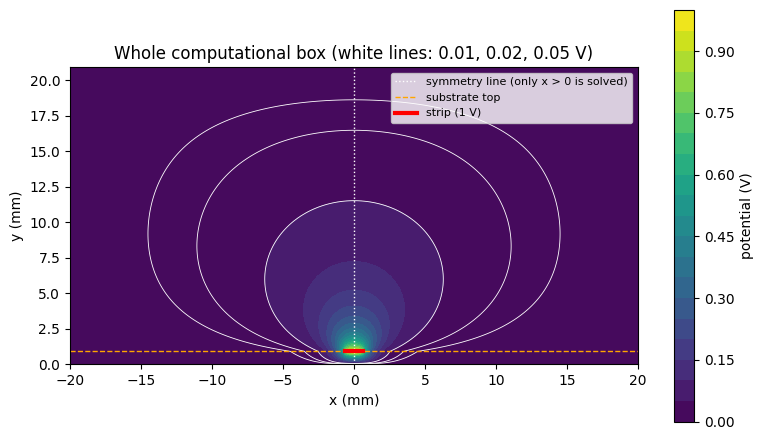

In [ ]:
# Plot 2: the whole computational box, to show the walls are far away
figure, axes = plt.subplots(figsize=(8, 4.5))
filled = axes.contourf(x_mm, y_mm, full_V, levels=np.linspace(0, 1, 21), cmap="viridis")
axes.contour(x_mm, y_mm, full_V, levels=[0.01, 0.02, 0.05], colors="white", linewidths=0.6)
axes.axvline(0, color="white", linestyle=":", linewidth=1, label="symmetry line (only x > 0 is solved)")
draw_line_geometry(axes, finest["grid"])
axes.set(aspect="equal", xlabel="x (mm)", ylabel="y (mm)",
         title="Whole computational box (white lines: 0.01, 0.02, 0.05 V)")
axes.legend(loc="upper right", fontsize=8)
figure.colorbar(filled, ax=axes, label="potential (V)")
figure.tight_layout()
figure.savefig("figures/microstrip_potential_box.png", dpi=200)
plt.show()

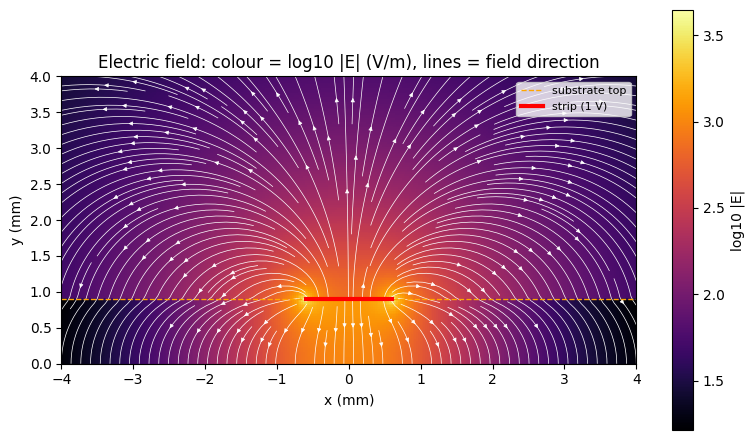

In [ ]:
# Plot 3: electric field, E = -grad V (V/m), with field lines
grid = finest["grid"]
field_y, field_x = np.gradient(-full_V, grid.dx * 1e-3)
field_magnitude = np.hypot(field_x, field_y)

# Keep only the 8 mm x 4 mm window around the strip, so the field lines are drawn where they matter.
in_x = np.abs(x_mm) <= 4
in_y = y_mm <= 4
x_window, y_window = x_mm[in_x], y_mm[in_y]
field_x_window = field_x[np.ix_(in_y, in_x)]
field_y_window = field_y[np.ix_(in_y, in_x)]

figure, axes = plt.subplots(figsize=(8, 4.5))
shown = axes.pcolormesh(x_window, y_window, np.log10(field_magnitude[np.ix_(in_y, in_x)] + 1),
                        cmap="inferno", shading="auto")
axes.streamplot(x_window, y_window, field_x_window, field_y_window,
                color="white", density=2.0, linewidth=0.5, arrowsize=0.6)
draw_line_geometry(axes, grid)
axes.set(xlim=(-4, 4), ylim=(0, 4), aspect="equal", xlabel="x (mm)", ylabel="y (mm)",
         title="Electric field: colour = log10 |E| (V/m), lines = field direction")
axes.legend(loc="upper right", fontsize=8)
figure.colorbar(shown, ax=axes, label="log10 |E|")
figure.tight_layout()
figure.savefig("figures/microstrip_field.png", dpi=200)
plt.show()

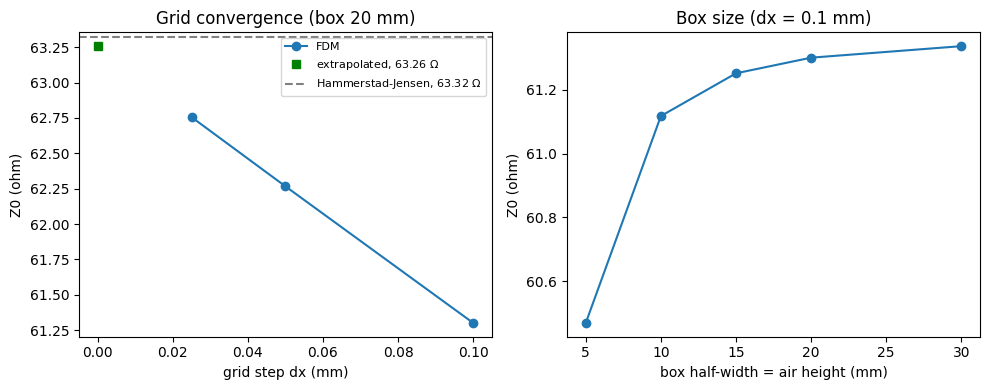

In [ ]:
# Plot 4: grid convergence and box size
figure, (left_axes, right_axes) = plt.subplots(1, 2, figsize=(10, 4))

left_axes.plot(grid_steps_mm, [result["Z0"] for result in results], "o-", label="FDM")
left_axes.plot(0, Z0_extrapolated, "s", color="green", label=f"extrapolated, {Z0_extrapolated:.2f} $\\Omega$")
left_axes.axhline(reference_Z0, color="grey", linestyle="--", label=f"Hammerstad-Jensen, {reference_Z0:.2f} $\\Omega$")
left_axes.set(xlabel="grid step dx (mm)", ylabel="Z0 (ohm)", title="Grid convergence (box 20 mm)")
left_axes.legend(fontsize=8)

right_axes.plot(box_sizes_mm, box_study, "o-")
right_axes.set(xlabel="box half-width = air height (mm)", ylabel="Z0 (ohm)", title="Box size (dx = 0.1 mm)")

figure.tight_layout()
figure.savefig("figures/microstrip_convergence.png", dpi=200)
plt.show()

## 9. Summary for the report

In [ ]:
print("Code specifications")
print(f"  grid step dx = dy             : {', '.join(str(step) for step in grid_steps_mm)} mm")
for result in results:
    print(f"  grid (half domain) at {result['dx']:<5} mm : {result['grid_shape'][0]} x {result['grid_shape'][1]} nodes, "
          f"{result['iterations']} iterations, {result['seconds']:.1f} s")
print(f"  box: half-width {box_half_width_mm} mm, air height {air_height_mm} mm")
print(f"  error tolerance               : {tolerance} V (largest change of any node in one sweep)")
print(f"  total computation time        : {sum(result['seconds'] for result in results):.1f} s")
print()
print("Results")
print(f"  Z0 (finest grid)              : {results[-1]['Z0']:.2f} ohm")
print(f"  Z0 (extrapolated)             : {Z0_extrapolated:.2f} ohm")
print(f"  effective permittivity        : {effective_permittivity_extrapolated:.3f}")
print(f"  Hammerstad-Jensen             : {reference_Z0:.2f} ohm, {reference_effective_permittivity:.3f}")

Code specifications
  grid step dx = dy             : 0.1, 0.05, 0.025 mm
  grid (half domain) at 0.1   mm : 210 x 201 nodes, 1126 iterations, 3.6 s
  grid (half domain) at 0.05  mm : 419 x 401 nodes, 1077 iterations, 18.3 s
  grid (half domain) at 0.025 mm : 837 x 801 nodes, 1951 iterations, 128.6 s
  box: half-width 20.0 mm, air height 20.0 mm
  error tolerance               : 1e-06 V (largest change of any node in one sweep)
  total computation time        : 150.4 s

Results
  Z0 (finest grid)              : 62.76 ohm
  Z0 (extrapolated)             : 63.26 ohm
  effective permittivity        : 3.035
  Hammerstad-Jensen             : 63.32 ohm, 3.039


# Part (b): stripline

**Line:** stripline, $\epsilon_r = 9$, $h = 0.9$ mm, $W = 1.2$ mm.

From the figure, $h$ is the distance from the strip to each ground plate, so the plates are
$b = 2h = 1.8$ mm apart and the strip is exactly halfway between them.

**What changes from the microstrip.** The strip is surrounded by one material only. Every capacitance then
scales with $\epsilon_r$, so $C = \epsilon_r C_0$ and one solve is enough:

$$Z_0 = \frac{1}{c\sqrt{C\,C_0}} = \frac{\sqrt{\epsilon_r}}{c\,C}, \qquad \epsilon_{\text{eff}} = \epsilon_r.$$

The solver, the Gauss's law charge and the grid refinement from Part (a) are reused as they are.
Only the grid is new: ground plates at the bottom and top rows, the strip on the middle row, and every
link has permittivity $\epsilon_r$. The left-right symmetry is used again (right half only).

You can run this part without the slow Part (a) runs: run the first code cell (imports and settings)
and the cells of sections 1 to 4 (they only define functions), then the cells below.

**Assumptions:** zero strip thickness; lossless materials; the ground plates are closed by grounded side
walls far from the strip (checked below; the field of a stripline dies away quickly to the sides).

In [ ]:
stripline_relative_permittivity = 9.0
stripline_strip_to_ground_mm = 0.9      # h: strip to each ground plate
stripline_strip_width_mm = 1.2
stripline_box_half_width_mm = 8.0       # centre of the strip to the side wall
stripline_grid_steps_mm = [0.05, 0.025, 0.0125]


def build_stripline_grid(relative_permittivity, dx, box_half_width_mm):
    strip_row = round(stripline_strip_to_ground_mm / dx)
    half_strip_columns = round(stripline_strip_width_mm / 2 / dx)
    rows = 2 * strip_row + 1
    columns = round(box_half_width_mm / dx) + 1

    V = np.zeros((rows, columns))
    is_fixed = np.zeros((rows, columns), dtype=bool)
    is_fixed[0, :] = True    # bottom ground plate
    is_fixed[-1, :] = True   # top ground plate
    is_fixed[:, -1] = True   # side wall

    V[strip_row, :half_strip_columns + 1] = 1.0
    is_fixed[strip_row, :half_strip_columns + 1] = True

    # One material everywhere, so every link has the same permittivity.
    vertical_link_permittivity = np.full(rows - 1, relative_permittivity)
    horizontal_link_permittivity = np.full(rows, relative_permittivity)

    return Grid(V, is_fixed, vertical_link_permittivity, horizontal_link_permittivity,
                dx, strip_row, half_strip_columns)


def stripline_impedance(dx, box_half_width_mm=stripline_box_half_width_mm, previous=None):
    start = time.perf_counter()
    grid = build_stripline_grid(stripline_relative_permittivity, dx, box_half_width_mm)
    start_V = None if previous is None else refine_potential(previous["V"], grid.V.shape)
    V, iterations = solve_laplace(grid, tolerance, start_V)
    C = strip_charge(V, grid)
    return {
        "dx": dx,
        "Z0": np.sqrt(stripline_relative_permittivity) / (SPEED_OF_LIGHT * C),
        "C": C,
        "grid_shape": V.shape,
        "iterations": iterations,
        "seconds": time.perf_counter() - start,
        "V": V, "grid": grid,
    }

### Reference: exact formula for a zero-thickness stripline

For a strip of zero thickness centred between infinitely wide plates, conformal mapping (Cohn, 1954)
gives the exact answer

$$Z_0 = \frac{30\pi}{\sqrt{\epsilon_r}}\,\frac{K(k)}{K(k')}, \qquad k = \operatorname{sech}\!\left(\frac{\pi W}{2b}\right),
\qquad k' = \sqrt{1-k^2},$$

where $K$ is the complete elliptic integral of the first kind. $K$ is computed with the
arithmetic-geometric mean: $K(k) = \pi / \big(2\,\text{AGM}(1, \sqrt{1-k^2})\big)$.

In [ ]:
def complete_elliptic_integral(modulus):
    arithmetic_mean, geometric_mean = 1.0, np.sqrt(1 - modulus**2)
    while abs(arithmetic_mean - geometric_mean) > 1e-15:
        arithmetic_mean, geometric_mean = ((arithmetic_mean + geometric_mean) / 2,
                                           np.sqrt(arithmetic_mean * geometric_mean))
    return np.pi / (2 * arithmetic_mean)


def exact_stripline_impedance(relative_permittivity, plate_spacing_mm, strip_width_mm):
    modulus = 1 / np.cosh(np.pi * strip_width_mm / (2 * plate_spacing_mm))
    complementary_modulus = np.sqrt(1 - modulus**2)
    return (30 * np.pi / np.sqrt(relative_permittivity)
            * complete_elliptic_integral(modulus) / complete_elliptic_integral(complementary_modulus))


stripline_reference_Z0 = exact_stripline_impedance(
    stripline_relative_permittivity, 2 * stripline_strip_to_ground_mm, stripline_strip_width_mm)
print(f"Exact (Cohn) stripline: Z0 = {stripline_reference_Z0:.3f} ohm")

Exact (Cohn) stripline: Z0 = 28.386 ohm


### Run on three grids, then extrapolate

In [ ]:
stripline_results = []
for dx in stripline_grid_steps_mm:
    result = stripline_impedance(dx, previous=stripline_results[-1] if stripline_results else None)
    stripline_results.append(result)
    print(f"dx = {dx:<7} mm  grid {result['grid_shape'][0]} x {result['grid_shape'][1]}  "
          f"iterations {result['iterations']:>5}  time {result['seconds']:6.1f} s  Z0 = {result['Z0']:.3f} ohm")

Z_coarse, Z_medium, Z_fine = (result["Z0"] for result in stripline_results)
stripline_order = np.log2((Z_coarse - Z_medium) / (Z_medium - Z_fine))
stripline_Z0_extrapolated = Z_fine + (Z_fine - Z_medium) / (2 ** stripline_order - 1)
print(f"observed order of convergence p = {stripline_order:.2f}")
print(f"Z0 extrapolated to dx -> 0      = {stripline_Z0_extrapolated:.2f} ohm")
print(f"exact (Cohn)                    = {stripline_reference_Z0:.2f} ohm  "
      f"(difference {100 * (stripline_Z0_extrapolated - stripline_reference_Z0) / stripline_reference_Z0:+.2f} %)")

dx = 0.05    mm  grid 37 x 161  iterations   324  time    0.2 s  Z0 = 27.864 ohm
dx = 0.025   mm  grid 73 x 321  iterations   413  time    0.7 s  Z0 = 28.114 ohm
dx = 0.0125  mm  grid 145 x 641  iterations   740  time    5.1 s  Z0 = 28.240 ohm
observed order of convergence p = 0.99
Z0 extrapolated to dx -> 0      = 28.37 ohm
exact (Cohn)                    = 28.39 ohm  (difference -0.06 %)


### Does the side wall matter?

The real stripline has no side walls. Moving the wall further out on the 0.05 mm grid:

In [ ]:
stripline_wall_distances_mm = [2, 3, 4, 6, 8, 12]
stripline_wall_study = []
for distance in stripline_wall_distances_mm:
    stripline_wall_study.append(stripline_impedance(0.05, box_half_width_mm=distance)["Z0"])
    print(f"side wall at {distance:>2} mm: Z0 = {stripline_wall_study[-1]:.4f} ohm")

side wall at  2 mm: Z0 = 27.7379 ohm
side wall at  3 mm: Z0 = 27.8599 ohm
side wall at  4 mm: Z0 = 27.8636 ohm
side wall at  6 mm: Z0 = 27.8638 ohm
side wall at  8 mm: Z0 = 27.8638 ohm
side wall at 12 mm: Z0 = 27.8638 ohm


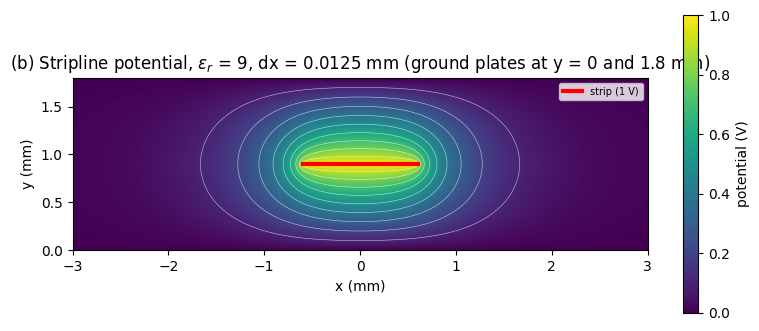

In [ ]:
# Potential plot for the stripline (finest grid, mirrored to show the whole line)
finest_stripline = stripline_results[-1]
plot_potential(finest_stripline["V"], finest_stripline["grid"],
               f"(b) Stripline potential, $\\epsilon_r$ = {stripline_relative_permittivity:g}, "
               f"dx = {finest_stripline['dx']} mm (ground plates at y = 0 and 1.8 mm)",
               "stripline_potential.png", x_limit_mm=3, y_top_mm=2 * stripline_strip_to_ground_mm,
               )

In [ ]:
print("Stripline: code specifications")
for result in stripline_results:
    print(f"  dx = {result['dx']:<7} mm : {result['grid_shape'][0]} x {result['grid_shape'][1]} nodes (half domain), "
          f"{result['iterations']} iterations, {result['seconds']:.1f} s")
print(f"  side wall {stripline_box_half_width_mm} mm from the centre, tolerance {tolerance} V")
print(f"  total time {sum(result['seconds'] for result in stripline_results):.1f} s")
print(f"Stripline Z0: finest grid {stripline_results[-1]['Z0']:.2f} ohm, extrapolated {stripline_Z0_extrapolated:.2f} ohm, "
      f"exact {stripline_reference_Z0:.2f} ohm")

Stripline: code specifications
  dx = 0.05    mm : 37 x 161 nodes (half domain), 324 iterations, 0.2 s
  dx = 0.025   mm : 73 x 321 nodes (half domain), 413 iterations, 0.7 s
  dx = 0.0125  mm : 145 x 641 nodes (half domain), 740 iterations, 5.1 s
  side wall 8.0 mm from the centre, tolerance 1e-06 V
  total time 5.9 s
Stripline Z0: finest grid 28.24 ohm, extrapolated 28.37 ohm, exact 28.39 ohm


In [ ]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-3.5-flash-lite', 'google/gemin…

# Part (c): grounded coplanar waveguide (GCPW)

**Line:** GCPW, $\epsilon_r = 2.5$, $h = 1.3$ mm, $W = 0.8$ mm, $S = 0.3$ mm.

The centre strip ($W$) lies on top of the substrate with a gap $S$ on each side. Beyond the gaps are two
top ground planes, and there is a ground plane under the substrate as well. All grounds are at 0 V.

**What changes from the microstrip.** The grid is the microstrip grid plus the two top grounds, which are
fixed 0 V nodes on the interface row, starting $W/2 + S$ from the centre and running to the side wall.
Like the microstrip, the field is partly in air and partly in the substrate, so we solve twice ($C$ and $C_0$).

The Gauss rectangle has to fit inside the gap, so it is drawn only 2 cells away from the strip.
The gap is 6 cells wide on the coarsest grid (0.05 mm), so the rectangle never touches a top ground.

**Assumptions:** zero metal thickness; lossless materials; the top grounds are wide enough to reach the
side walls of the box; all grounds are at the same potential (in a real board, vias tie them together).

In [ ]:
gcpw_relative_permittivity = 2.5
gcpw_substrate_height_mm = 1.3
gcpw_strip_width_mm = 0.8
gcpw_gap_mm = 0.3
gcpw_box_half_width_mm = 10.0
gcpw_air_height_mm = 10.0
gcpw_grid_steps_mm = [0.05, 0.025, 0.0125]
gcpw_gauss_margin_cells = 2


def build_gcpw_grid(relative_permittivity, dx, box_half_width_mm, air_height_mm):
    substrate_rows = round(gcpw_substrate_height_mm / dx)
    half_strip_columns = round(gcpw_strip_width_mm / 2 / dx)
    top_ground_start_column = round((gcpw_strip_width_mm / 2 + gcpw_gap_mm) / dx)
    rows = substrate_rows + round(air_height_mm / dx) + 1
    columns = round(box_half_width_mm / dx) + 1

    V = np.zeros((rows, columns))
    is_fixed = np.zeros((rows, columns), dtype=bool)
    is_fixed[0, :] = True    # bottom ground plane
    is_fixed[-1, :] = True   # top wall of the box
    is_fixed[:, -1] = True   # side wall

    strip_row = substrate_rows
    V[strip_row, :half_strip_columns + 1] = 1.0
    is_fixed[strip_row, :half_strip_columns + 1] = True
    is_fixed[strip_row, top_ground_start_column:] = True   # top ground plane, V stays 0

    vertical_link_permittivity = np.where(np.arange(rows - 1) < substrate_rows,
                                          relative_permittivity, 1.0)
    horizontal_link_permittivity = np.where(np.arange(rows) < substrate_rows,
                                            relative_permittivity, 1.0)
    horizontal_link_permittivity[substrate_rows] = (1 + relative_permittivity) / 2

    return Grid(V, is_fixed, vertical_link_permittivity, horizontal_link_permittivity,
                dx, strip_row, half_strip_columns)


def gcpw_impedance(dx, box_half_width_mm=gcpw_box_half_width_mm,
                   air_height_mm=gcpw_air_height_mm, previous=None):
    start = time.perf_counter()
    grid = build_gcpw_grid(gcpw_relative_permittivity, dx, box_half_width_mm, air_height_mm)
    air_grid = build_gcpw_grid(1.0, dx, box_half_width_mm, air_height_mm)

    if previous is None:
        start_V = start_V_air = None
    else:
        start_V = refine_potential(previous["V"], grid.V.shape)
        start_V_air = refine_potential(previous["V_air"], grid.V.shape)

    V, iterations = solve_laplace(grid, tolerance, start_V)
    V_air, iterations_air = solve_laplace(air_grid, tolerance, start_V_air)
    C = strip_charge(V, grid, gcpw_gauss_margin_cells)
    C0 = strip_charge(V_air, air_grid, gcpw_gauss_margin_cells)

    return {
        "dx": dx,
        "Z0": 1 / (SPEED_OF_LIGHT * np.sqrt(C * C0)),
        "effective_permittivity": C / C0,
        "C": C, "C0": C0,
        "grid_shape": V.shape,
        "iterations": iterations + iterations_air,
        "seconds": time.perf_counter() - start,
        "V": V, "V_air": V_air, "grid": grid,
    }

In [ ]:
!lscpu | grep "Model name"; !nproc; !free -h | grep Mem
import sys; print(sys.version)

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
/bin/bash: line 1: !nproc: command not found
/bin/bash: line 1: !free: command not found
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


### Reference: conformal-mapping formula

For a GCPW with very wide top grounds and open air above, conformal mapping gives (Ghione and Naldi, 1987;
also in Wadell's *Transmission Line Design Handbook*), with $a = W/2$ and $b = W/2 + S$:

$$k = \frac{a}{b}, \qquad k_3 = \frac{\tanh(\pi a / 2h)}{\tanh(\pi b / 2h)}, \qquad
q = \frac{K(k')}{K(k)}\,\frac{K(k_3)}{K(k_3')}$$

$$\epsilon_{\text{eff}} = \frac{1 + \epsilon_r q}{1 + q}, \qquad
Z_0 = \frac{60\pi}{\sqrt{\epsilon_{\text{eff}}}}\,\frac{1}{K(k)/K(k') + K(k_3)/K(k_3')}$$

This formula splits the field into separate air and substrate parts, so it is an approximation (good to
a few per cent), not an exact answer like the stripline formula. It uses `complete_elliptic_integral`
from Part (b), so run that cell first if you skipped Part (b).

In [ ]:
def conformal_gcpw_impedance(relative_permittivity, substrate_height_mm, strip_width_mm, gap_mm):
    a = strip_width_mm / 2
    b = strip_width_mm / 2 + gap_mm
    k = a / b
    k3 = np.tanh(np.pi * a / (2 * substrate_height_mm)) / np.tanh(np.pi * b / (2 * substrate_height_mm))
    complementary = lambda modulus: np.sqrt(1 - modulus**2)
    ratio = lambda modulus: complete_elliptic_integral(modulus) / complete_elliptic_integral(complementary(modulus))
    q = ratio(k3) / ratio(k)
    effective_permittivity = (1 + relative_permittivity * q) / (1 + q)
    Z0 = 60 * np.pi / np.sqrt(effective_permittivity) / (ratio(k) + ratio(k3))
    return Z0, effective_permittivity


gcpw_reference_Z0, gcpw_reference_effective_permittivity = conformal_gcpw_impedance(
    gcpw_relative_permittivity, gcpw_substrate_height_mm, gcpw_strip_width_mm, gcpw_gap_mm)
print(f"Conformal mapping GCPW: Z0 = {gcpw_reference_Z0:.2f} ohm, "
      f"effective permittivity = {gcpw_reference_effective_permittivity:.3f}")

Conformal mapping GCPW: Z0 = 79.17 ohm, effective permittivity = 1.785


### Box size, then three grids

In [ ]:
gcpw_box_sizes_mm = [2, 4, 6, 10, 15]
gcpw_box_study = []
for size in gcpw_box_sizes_mm:
    gcpw_box_study.append(gcpw_impedance(0.05, box_half_width_mm=size, air_height_mm=size)["Z0"])
    print(f"box {size:>2} mm: Z0 = {gcpw_box_study[-1]:.3f} ohm")

box  2 mm: Z0 = 74.373 ohm
box  4 mm: Z0 = 75.296 ohm
box  6 mm: Z0 = 75.468 ohm
box 10 mm: Z0 = 75.557 ohm
box 15 mm: Z0 = 75.585 ohm


In [ ]:
gcpw_results = []
for dx in gcpw_grid_steps_mm:
    result = gcpw_impedance(dx, previous=gcpw_results[-1] if gcpw_results else None)
    gcpw_results.append(result)
    print(f"dx = {dx:<7} mm  grid {result['grid_shape'][0]} x {result['grid_shape'][1]}  "
          f"iterations {result['iterations']:>5}  time {result['seconds']:6.1f} s  "
          f"Z0 = {result['Z0']:.3f} ohm  eff. permittivity = {result['effective_permittivity']:.4f}")

Z_coarse, Z_medium, Z_fine = (result["Z0"] for result in gcpw_results)
gcpw_order = np.log2((Z_coarse - Z_medium) / (Z_medium - Z_fine))
gcpw_Z0_extrapolated = Z_fine + (Z_fine - Z_medium) / (2 ** gcpw_order - 1)
e_coarse, e_medium, e_fine = (result["effective_permittivity"] for result in gcpw_results)
gcpw_effective_permittivity_extrapolated = e_fine + (e_fine - e_medium) / (2 ** gcpw_order - 1)
print(f"observed order of convergence p = {gcpw_order:.2f}")
print(f"Z0 extrapolated to dx -> 0      = {gcpw_Z0_extrapolated:.2f} ohm, "
      f"effective permittivity {gcpw_effective_permittivity_extrapolated:.3f}")
print(f"conformal mapping               = {gcpw_reference_Z0:.2f} ohm  "
      f"(difference {100 * (gcpw_Z0_extrapolated - gcpw_reference_Z0) / gcpw_reference_Z0:+.2f} %)")

dx = 0.05    mm  grid 227 x 201  iterations   950  time    3.6 s  Z0 = 75.557 ohm  eff. permittivity = 1.7836
dx = 0.025   mm  grid 453 x 401  iterations  1173  time   17.6 s  Z0 = 77.306 ohm  eff. permittivity = 1.7842
dx = 0.0125  mm  grid 905 x 801  iterations  2096  time  147.9 s  Z0 = 78.177 ohm  eff. permittivity = 1.7844
observed order of convergence p = 1.01
Z0 extrapolated to dx -> 0      = 79.04 ohm, effective permittivity 1.785
conformal mapping               = 79.17 ohm  (difference -0.17 %)


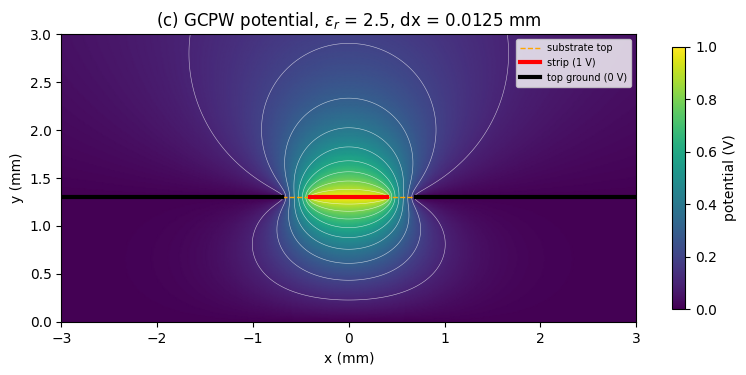

In [ ]:
# Potential plot for the GCPW (finest grid, mirrored to show the whole line)
finest_gcpw = gcpw_results[-1]
plot_potential(finest_gcpw["V"], finest_gcpw["grid"],
               f"(c) GCPW potential, $\\epsilon_r$ = {gcpw_relative_permittivity}, dx = {finest_gcpw['dx']} mm",
               "gcpw_potential.png", x_limit_mm=3, y_top_mm=3,
               substrate_top_mm=gcpw_substrate_height_mm,
               top_ground_start_mm=gcpw_strip_width_mm / 2 + gcpw_gap_mm)

# All three lines together

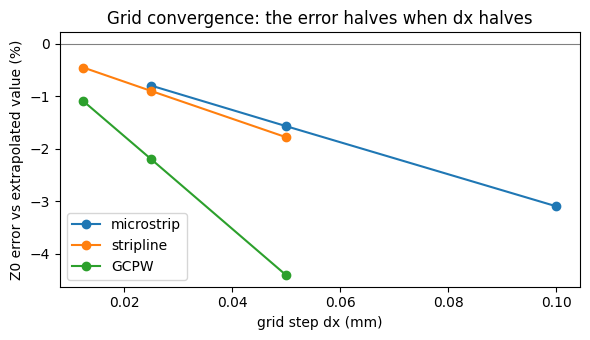

line         Z0 finest (ohm)  Z0 extrapolated  eff. perm.  reference  diff %
microstrip             62.76            63.26       3.035      63.32   -0.10
stripline              28.24            28.37       9.000      28.39   -0.06
GCPW                   78.18            79.04       1.785      79.17   -0.17


In [ ]:
# Grid convergence of all three lines in one picture: Z0 on each grid divided by its extrapolated value
figure, axes = plt.subplots(figsize=(6, 3.5))
for name, line_results, extrapolated in [("microstrip", results, Z0_extrapolated),
                                         ("stripline", stripline_results, stripline_Z0_extrapolated),
                                         ("GCPW", gcpw_results, gcpw_Z0_extrapolated)]:
    steps = [result["dx"] for result in line_results]
    error_percent = [100 * (result["Z0"] - extrapolated) / extrapolated for result in line_results]
    axes.plot(steps, error_percent, "o-", label=name)
axes.axhline(0, color="grey", linewidth=0.8)
axes.set(xlabel="grid step dx (mm)", ylabel="Z0 error vs extrapolated value (%)",
         title="Grid convergence: the error halves when dx halves")
axes.legend()
figure.tight_layout()
figure.savefig("figures/all_convergence.png", dpi=200)
plt.show()

print(f"{'line':<11}{'Z0 finest (ohm)':>17}{'Z0 extrapolated':>17}{'eff. perm.':>12}{'reference':>11}{'diff %':>8}")
for name, finest_Z0, extrapolated, effective, reference in [
        ("microstrip", results[-1]["Z0"], Z0_extrapolated, effective_permittivity_extrapolated, reference_Z0),
        ("stripline", stripline_results[-1]["Z0"], stripline_Z0_extrapolated, stripline_relative_permittivity, stripline_reference_Z0),
        ("GCPW", gcpw_results[-1]["Z0"], gcpw_Z0_extrapolated, gcpw_effective_permittivity_extrapolated, gcpw_reference_Z0)]:
    print(f"{name:<11}{finest_Z0:>17.2f}{extrapolated:>17.2f}{effective:>12.3f}{reference:>11.2f}"
          f"{100 * (extrapolated - reference) / reference:>8.2f}")